In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from concurrent.futures import ProcessPoolExecutor

from filters import highPassFilter

filename = './assets/2.png'
figsize = (12, 8)

In [2]:
image = cv.imread(filename)
assert image is not None
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)


def appendPositions(image):
    result = np.zeros(shape=(image.shape[0], image.shape[1], image.shape[2] + 2))
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            result[i, j] = [(i / image.shape[0] * 255), (j / image.shape[1] * 255), *image[i, j]]
    return result


data_with_positions = appendPositions(image)


def showRGB(ax, image, title, cmap=None):
    ax.imshow(image, cmap=cmap)
    ax.axis("off")
    ax.set_title(title)


def showGray(ax, image, title, cmap=None):
    ax.imshow(image, cmap='gray')
    ax.axis("off")
    ax.set_title(title)


def showKMeansWithoutPositions(ax, result, title):
    compactness, labels, centers = result
    centers = np.uint8(centers)
    segmented_image = centers[labels.flatten()].reshape(image.shape)  # type: ignore
    ax.imshow(segmented_image)
    ax.axis("off")
    ax.set_title(title)


def showKMeansWithPositions(ax, result, title):
    compactness, labels, centers = result
    centers = np.uint8(centers)
    segmented_image = centers[labels.flatten()].reshape(data_with_positions.shape)[:, :, 2:5]
    ax.imshow(segmented_image)
    ax.axis("off")
    ax.set_title(title)

## Бинаризация

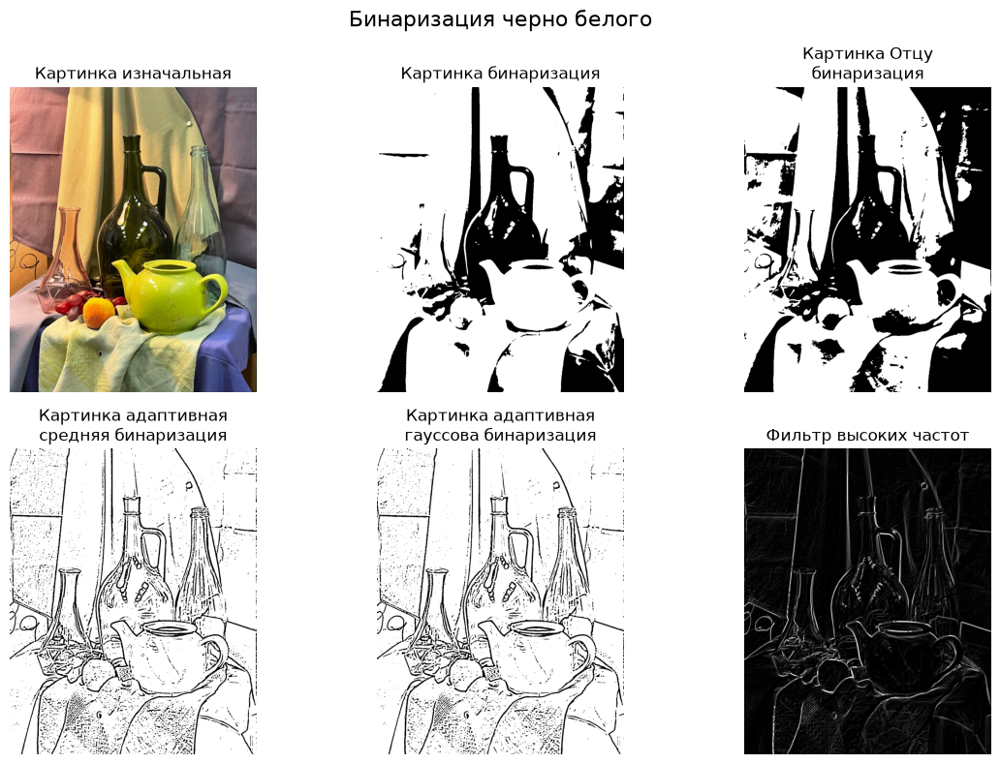

In [ ]:
image_gray = cv.cvtColor(image, cv.COLOR_RGB2GRAY)
image_gray_blur = cv.GaussianBlur(image_gray, (9, 9), 0)
fig, ax = plt.subplots(2, 3, figsize=figsize)
fig.suptitle('Бинаризация черно белого', fontsize=16)
showRGB(ax[0, 0], image, 'Картинка изначальная')
showGray(ax[0, 1], cv.threshold(image_gray_blur, 90, 255, type=cv.THRESH_BINARY)[1], 'Картинка бинаризация')
showGray(ax[0, 2], cv.threshold(image_gray_blur, 0, 255, type=cv.THRESH_BINARY +
        cv.THRESH_OTSU)[1], 'Картинка Отцу\nбинаризация')
showGray(ax[1, 0], cv.adaptiveThreshold(
    image_gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 7, 3), 'Картинка адаптивная\nсредняя бинаризация')
showGray(ax[1, 1], cv.adaptiveThreshold(
    image_gray_blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 3), 'Картинка адаптивная\nгауссова бинаризация')
showGray(ax[1, 2], highPassFilter(cv.GaussianBlur(image_gray, (7, 7), 0))[0], 'Фильтр высоких частот')
plt.tight_layout()
plt.show()

In [217]:
    # # 1.2 нейрокод
    # def highPassFilter(image, sigma=3):
    #     """Возвращает [high, low] — высокочастотную (границы) и низкочастотную (фон) составляющие."""
    #     low  = cv.GaussianBlur(image, (0, 0), sigma)
    #     high = cv.subtract(image, low)
    #     high = cv.normalize(high, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
    #     return high, low

    # def kmeans_color_segmentation(image_bgr, features, K=5):
    #     """
    #     image_bgr : исходное цветное (H,W,3) BGR
    #     features  : (H*W, C) float32 — признаки для кластеризации
    #     """
    #     H, W = image_bgr.shape[:2]
    #     criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.5)
    #     _, labels, centers = cv.kmeans(features, K, None, criteria, 10,
    #                                 cv.KMEANS_PP_CENTERS)
    #     labels = labels.flatten()

    #     # средний цвет каждого кластера по исходной картинке
    #     palette = np.zeros((K, 3), np.float32)
    #     flat_img = image_bgr.reshape(-1, 3).astype(np.float32)
    #     for k in range(K):
    #         m = labels == k
    #         palette[k] = flat_img[m].mean(axis=0) if m.any() else 0

    #     seg = palette[labels].reshape(H, W, 3).astype(np.uint8)
    #     return seg, labels.reshape(H, W), centers

    # image_gray      = cv.cvtColor(image, cv.COLOR_RGB2GRAY)
    # image_gray_blur = cv.GaussianBlur(image_gray, (9, 9), 0)

    # fig, ax = plt.subplots(2, 4, figsize=(16, 8))
    # fig.suptitle('Частоты → границы → цветная сегментация', fontsize=16)

    # ax[0, 0].imshow(image); ax[0, 0].axis("off")
    # ax[0, 0].set_title('Исходное')

    # showGray(ax[0, 1], cv.threshold(image_gray_blur, 90, 255, cv.THRESH_BINARY)[1],
    #         'Бинаризация 90')
    # showGray(ax[0, 2], cv.threshold(image_gray_blur, 0, 255,
    #         cv.THRESH_BINARY + cv.THRESH_OTSU)[1], 'Otsu')
    # showGray(ax[1, 0], cv.adaptiveThreshold(image_gray_blur, 255,
    #         cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 7, 3), 'Адаптивная')

    # # --- частотное разложение ---
    # high, low = highPassFilter(image_gray_blur, sigma=3)
    # showGray(ax[1, 1], high, 'Высокие частоты')

    # sharpened    = cv.addWeighted(low, 1.0, high, 0.7, 0)
    # edges        = cv.Canny(high, 40, 120)
    # kernel       = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
    # edges_closed = cv.morphologyEx(edges, cv.MORPH_CLOSE, kernel, iterations=2)
    # showGray(ax[1, 2], edges_closed, 'Границы (замкнутые)')

    # # --- K-means: признаки = unsharp + edges + цвет (Lab a,b) ---
    # lab      = cv.cvtColor(image, cv.COLOR_RGB2LAB)
    # chroma   = lab[:, :, 1:].astype(np.float32)                      # (H,W,2)

    # feats = np.dstack([
    #     sharpened.astype(np.float32) / 255.0,
    #     edges_closed.astype(np.float32) / 255.0,
    #     chroma[:, :, 0] / 255.0,
    #     chroma[:, :, 1] / 255.0,
    # ]).reshape(-1, 4).astype(np.float32)

    # # нормировка, чтобы каналы были сопоставимы
    # feats = (feats - feats.mean(0)) / (feats.std(0) + 1e-6)

    # K = 10
    # criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.5)
    # _, labels, _ = cv.kmeans(feats, K, None, criteria, 10, cv.KMEANS_PP_CENTERS)
    # labels = labels.reshape(sharpened.shape)

    # # цветная визуализация по среднему цвету кластера
    # image_bgr = cv.cvtColor(image, cv.COLOR_RGB2BGR)
    # seg_bgr, _, _ = kmeans_color_segmentation(image_bgr, feats, K=K)
    # seg_rgb = cv.cvtColor(seg_bgr, cv.COLOR_BGR2RGB)

    # ax[1, 3].imshow(seg_rgb)
    # ax[1, 3].set_title(f'Цветная сегментация (K={K})')
    # ax[1, 3].axis("off")

    # plt.tight_layout()
    # plt.show()

## Выполнение kmeans только по цвету

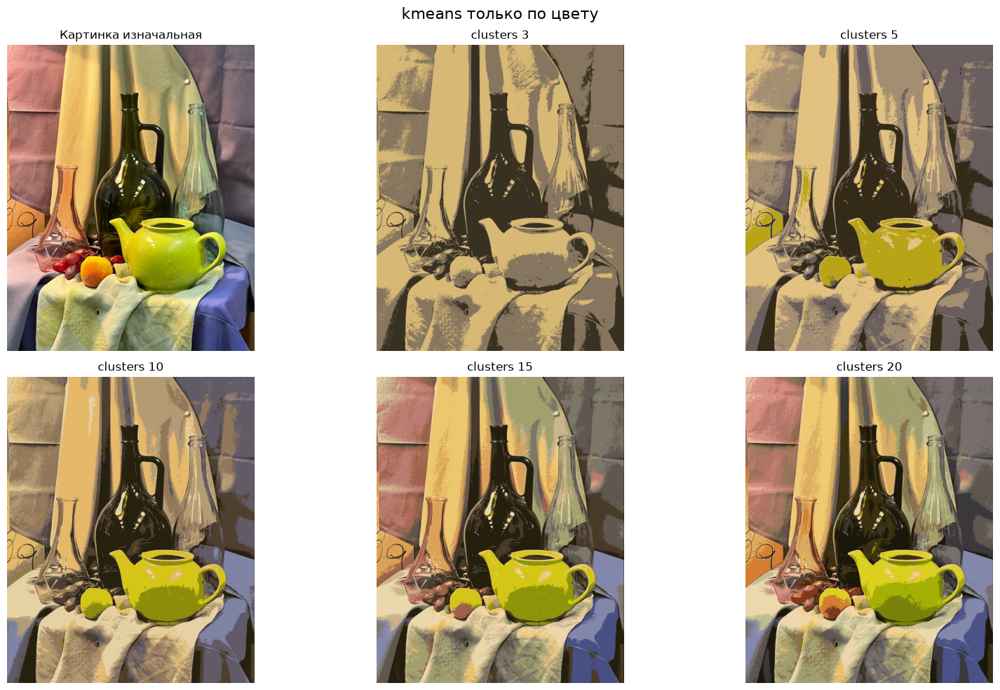

In [208]:
with ProcessPoolExecutor(max_workers=10) as ex:
    data_one_line = image.reshape((-1, 3)).astype(np.float32)
    criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.5)
    attempts = 10
    flags = cv.KMEANS_PP_CENTERS

    ks = [3, 5, 10, 15, 20]
    futures = []
    for k in ks:
        futures.append(ex.submit(cv.kmeans, data_one_line, k, None, criteria, attempts, flags))  # type: ignore

    fig, ax = plt.subplots(2, 3, figsize=figsize)
    fig.suptitle('kmeans только по цвету', fontsize=16)
    showRGB(ax[0, 0], image, 'Картинка изначальная')
    axes = [ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1], ax[1, 2]]
    for ax, future, k in zip(axes, futures, ks):
        showKMeansWithoutPositions(ax, future.result(), f'clusters {k}')
    plt.tight_layout()
    plt.show()

## Выполнение kmeans по цвету и позиции

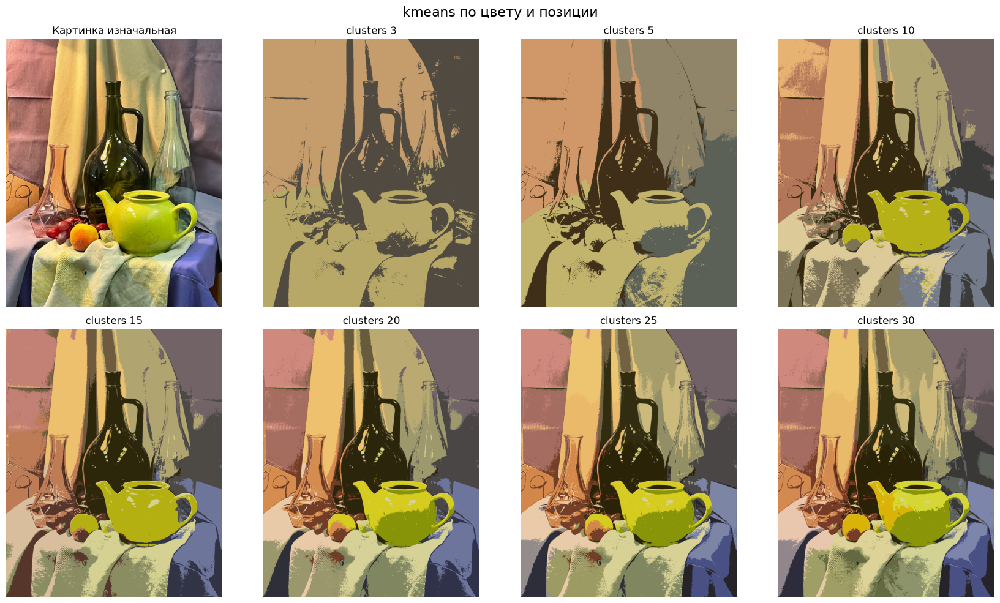

In [ ]:
with ProcessPoolExecutor(max_workers=10) as ex:
    data_one_line = data_with_positions.reshape((-1, 5)).astype(np.float32)
    criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.5)
    attempts = 10
    flags = cv.KMEANS_PP_CENTERS
    ks = [3, 5, 10, 15, 20, 25, 30]
    futures = []
    for k in ks:
        futures.append(ex.submit(cv.kmeans, data_one_line, k, None, criteria, attempts, flags))  # type: ignore

    fig, ax = plt.subplots(2, 4, figsize=figsize)
    fig.suptitle('kmeans по цвету и позиции', fontsize=16)
    showRGB(ax[0, 0], image, 'Картинка изначальная')
    axes = [ax[0, 1], ax[0, 2], ax[0, 3], ax[1, 0], ax[1, 1], ax[1, 2], ax[1, 3]]
    for ax, future, k in zip(axes, futures, ks):
        showKMeansWithPositions(ax, future.result(), f'clusters {k}')
    plt.tight_layout()
    plt.show()

## Выполнение opencv.pyrMeanShiftFiltering по цвету и позиции

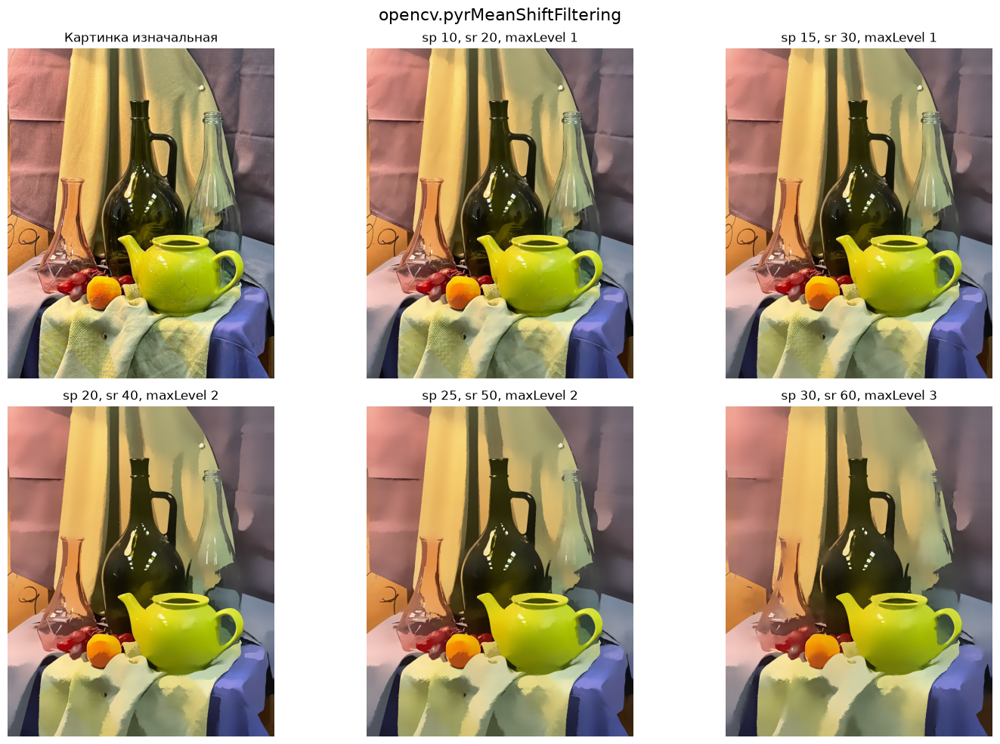

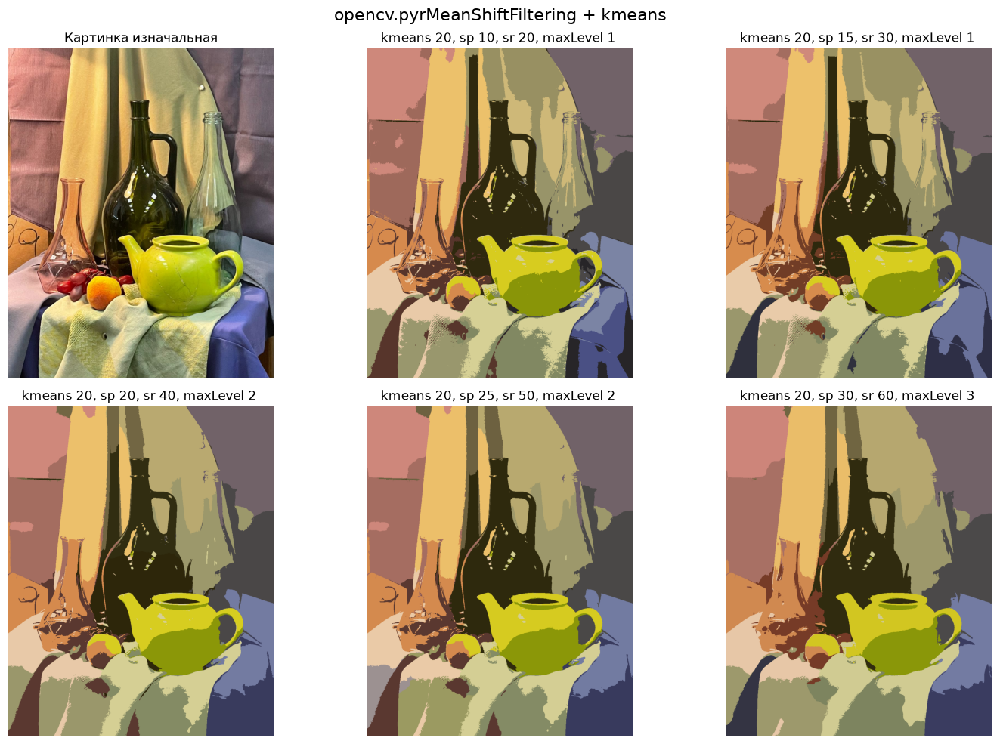

In [9]:
with ProcessPoolExecutor(max_workers=10) as ex:
    SP = np.array([10,  15,  20,  25,  30])
    SR = SP * 2
    MAX_LEVEL = [1,   1,   2,   2,   3]
    futures = []
    for sp, sr, maxLevel in zip(SP, SR, MAX_LEVEL):
        futures.append(ex.submit(cv.pyrMeanShiftFiltering, image, sp=sp, sr=sr, maxLevel=maxLevel))

    fig, ax = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('opencv.pyrMeanShiftFiltering', fontsize=16)
    showRGB(ax[0, 0], image, 'Картинка изначальная')
    axes = [ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1], ax[1, 2]]
    for ax, future, sp, sr, maxLevel in zip(axes, futures, SP, SR, MAX_LEVEL):
        showRGB(ax, future.result(), f'sp {sp}, sr {sr}, maxLevel {maxLevel}')
    plt.tight_layout()
    plt.show()

    criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.5)
    K = 20
    attempts = 10
    flags = cv.KMEANS_PP_CENTERS
    futures2 = []
    for future in futures:
        img = appendPositions(future.result()).reshape((-1, 5)).astype(np.float32)
        futures2.append(ex.submit(cv.kmeans, img, K, None, criteria, attempts, flags))  # type: ignore

    fig, ax = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('opencv.pyrMeanShiftFiltering + kmeans', fontsize=16)
    showRGB(ax[0, 0], image, 'Картинка изначальная')
    axes = [ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1], ax[1, 2]]
    for ax, future, sp, sr, maxLevel in zip(axes, futures2, SP, SR, MAX_LEVEL):
        showKMeansWithPositions(ax, future.result(),
                                f'kmeans {K}, sp {sp}, sr {sr}, maxLevel {maxLevel} ')
    plt.tight_layout()
    plt.show()

## Выполнение sklearn.cluster.MeanShift по цвету и позиции

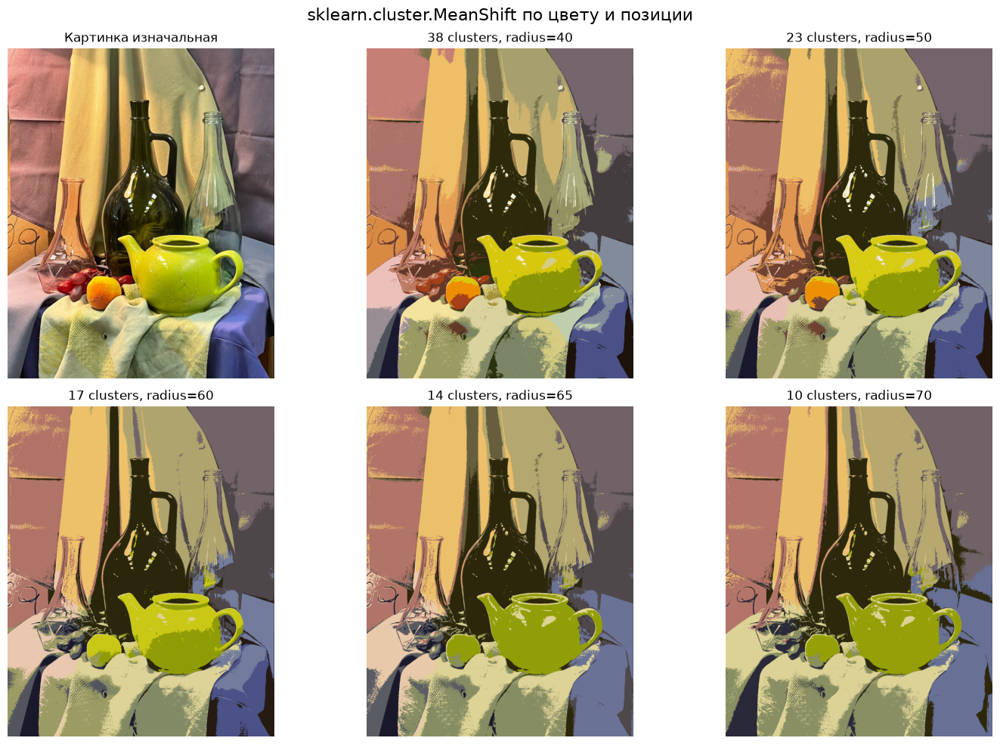

In [5]:
from sklearn.cluster import MeanShift, estimate_bandwidth

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('sklearn.cluster.MeanShift по цвету и позиции', fontsize=16)
showRGB(ax[0, 0], image, 'Картинка изначальная')

radiuses = [40, 50, 60, 65, 70]
axes = [ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1], ax[1, 2]]
data_one_line = data_with_positions.reshape((-1, 5)).astype(np.float32)
for ax, radius in zip(axes, radiuses):
    ms = MeanShift(bandwidth=radius, bin_seeding=True, n_jobs=-1).fit(data_one_line)

    colors = ms.cluster_centers_[:, 2:5].astype(np.uint8)
    n = len(colors)
    segmented = colors[ms.labels_].reshape(image.shape)
    showRGB(ax, segmented, f'{n} clusters, radius={radius}')
plt.tight_layout()
plt.show()


## Сегментация водоразделом

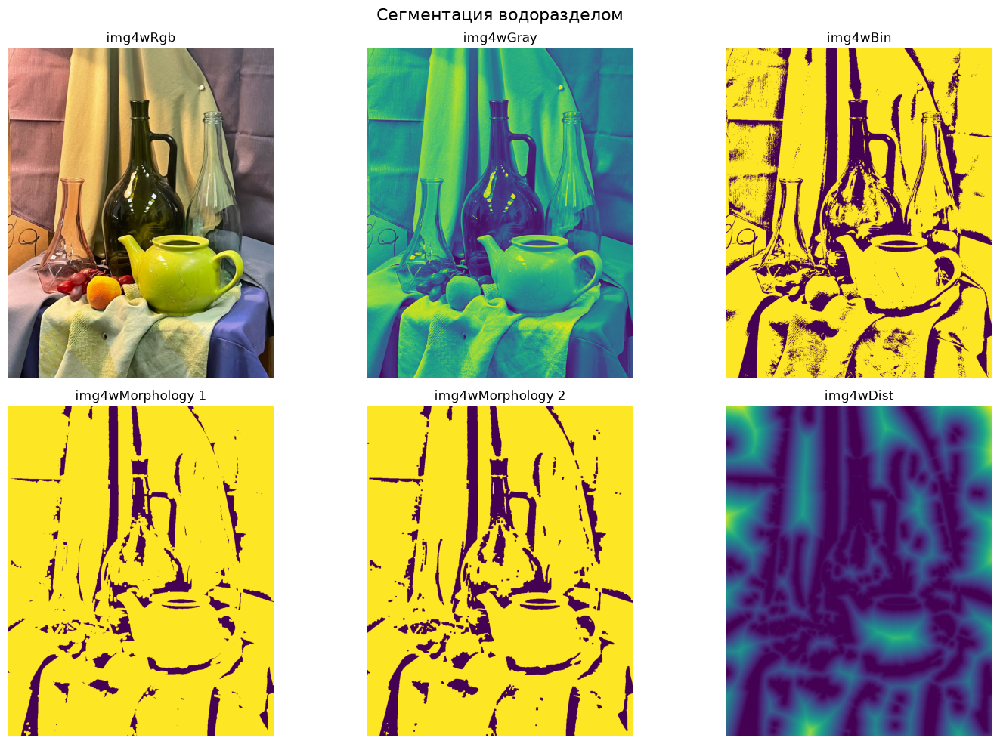

In [4]:
image4W = cv.imread('./assets/2.png')
assert image4W is not None

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Сегментация водоразделом', fontsize=16)

img4wRgb = cv.cvtColor(image4W, cv.COLOR_BGR2RGB)
showRGB(ax[0, 0], img4wRgb, 'img4wRgb')

img4wGray = cv.cvtColor(image4W, cv.COLOR_BGR2GRAY)
showRGB(ax[0, 1], img4wGray, 'img4wGray')

img4wBin = cv.adaptiveThreshold(img4wGray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 101, 20)
showRGB(ax[0, 2], img4wBin, 'img4wBin')

img4wMorphology = img4wBin
img4wMorphology = cv.morphologyEx(img4wMorphology, cv.MORPH_DILATE, np.ones((3, 3), np.uint8), iterations=3)
showRGB(ax[1, 0], img4wMorphology, 'img4wMorphology 1')
img4wMorphology = cv.morphologyEx(img4wMorphology, cv.MORPH_ERODE, np.ones((5, 5), np.uint))
showRGB(ax[1, 1], img4wMorphology, 'img4wMorphology 2')

img4wDist = cv.distanceTransform(img4wMorphology, cv.DIST_L2, 5)
showRGB(ax[1, 2], img4wDist, 'img4wDist')

plt.tight_layout()
plt.show()

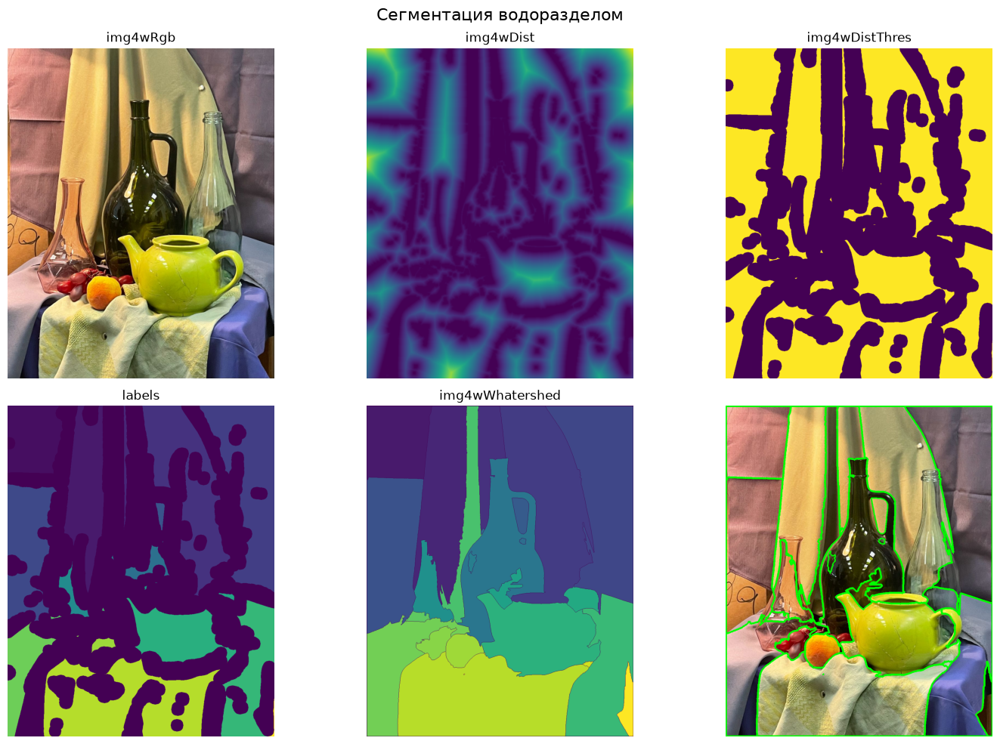

In [50]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Сегментация водоразделом', fontsize=16)

showRGB(ax[0, 0], img4wRgb, 'img4wRgb')
showRGB(ax[0, 1], img4wDist, 'img4wDist')

img4wDistThres = cv.threshold(img4wDist, 20, 255, cv.THRESH_BINARY)[1]
showRGB(ax[0, 2], img4wDistThres, 'img4wDistThres')

_, labels = cv.connectedComponents(img4wDistThres.astype(np.uint8))
showRGB(ax[1, 0], labels, 'labels')

img4wWhatershed = cv.watershed(img4wRgb, labels.astype(np.int32))
showRGB(ax[1, 1], img4wWhatershed, 'img4wWhatershed')

image_countours = img4wRgb.copy()
for label in np.unique(img4wWhatershed):
    if label == 0:
        continue
    mask = np.zeros(img4wWhatershed.shape, dtype="uint8")
    mask[img4wWhatershed == label] = 255
    cnts = cv.findContours(mask.copy(), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    cnts = cnts[0] if len(cnts) == 2 else cnts[1]
    cv.drawContours(image_countours, cnts, -1, (0, 255, 0), 3)

showRGB(ax[1, 2], image_countours, '', plt.cm.gray)

plt.tight_layout()
plt.show()

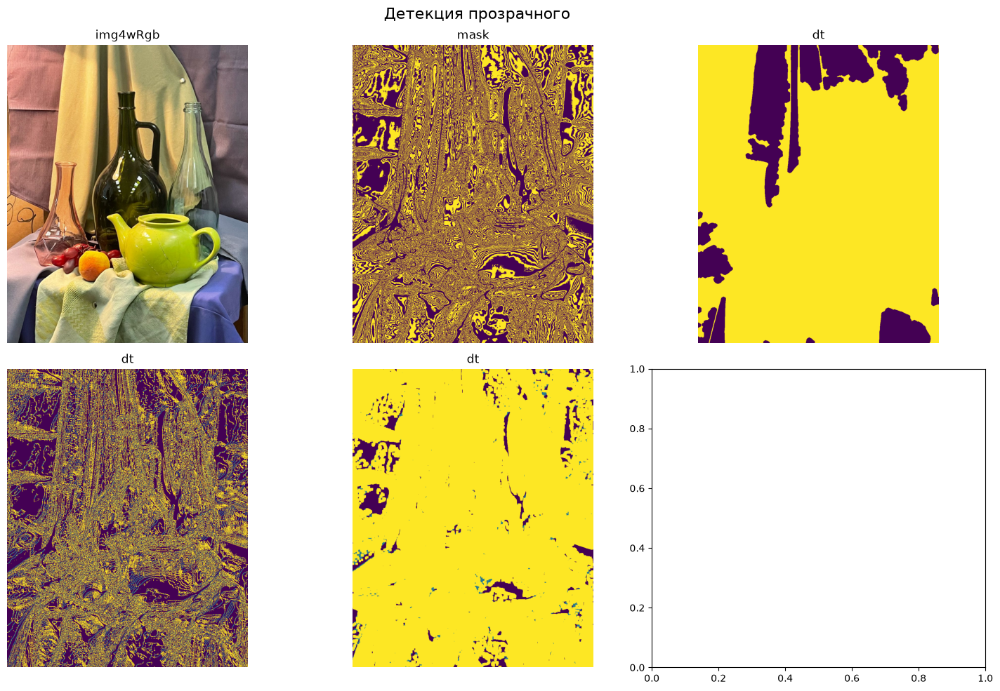

In [15]:
def detect_transparent(img_bgr):
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    hsv  = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)

    # 1) границы
    edges = cv.Canny(gray, 30, 100)
    edges = cv.dilate(edges, np.ones((3,3), np.uint8))

    # 2) блики
    glare = cv.inRange(hsv, (0,0,220), (180,40,255))

    # 3) локальная дисперсия (искажение текстуры)
    g = gray.astype(np.float32)
    m  = cv.blur(g, (15,15)); m2 = cv.blur(g*g, (15,15))
    var = m2 - m*m
    var = cv.normalize(var, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
    _, var_mask = cv.threshold(var, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # 4) объединяем
    combined = cv.bitwise_or(edges, glare)
    combined = cv.bitwise_or(combined, var_mask)

    # 5) морфология: закрыть и заполнить
    k = cv.getStructuringElement(cv.MORPH_ELLIPSE, (7,7))
    combined = cv.morphologyEx(combined, cv.MORPH_CLOSE, k, iterations=3)

    # 6) заполнить замкнутые области
    cnts,_ = cv.findContours(combined, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(gray)
    for c in cnts:
        if cv.contourArea(c) > 500:
            cv.drawContours(mask, [c], -1, 255, -1)

    # 7) фильтр по площади
    n, labels, stats, _ = cv.connectedComponentsWithStats(mask)
    clean = np.zeros_like(mask)
    for i in range(1, n):
        if stats[i, cv.CC_STAT_AREA] > 1000:
            clean[labels == i] = 255
    return clean

gray = img4wGray
mean = cv.blur(gray, (15,15))
sq_mean = cv.blur(gray*gray, (15,15))
variance = sq_mean - mean*mean
variance = cv.normalize(variance, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
_, mask = cv.threshold(variance, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Детекция прозрачного', fontsize=16)
showRGB(ax[0, 0], img4wRgb, 'img4wRgb')
showRGB(ax[0, 1], mask, 'mask')
showRGB(ax[0, 2], detect_transparent(img4wRgb), 'dt')
b = highPassFilter(mask)[0]
showRGB(ax[1, 0], b, 'dt')
edges = cv.dilate(b, np.ones((5,5), np.uint8),iterations=2)
# edges = cv.erode(b, np.ones((3,3), np.uint8))
showRGB(ax[1, 1], edges, 'dt')
plt.tight_layout()
plt.show()